
# Inventory Monitoring at Distribution Centers
## by Karol

One of the biggest challenges in distribution centers is inventory level monitoring. It's crucial for order fulfillment. Since distribution centers handle millions of packages, automating this process is essential. This project aims to develop a solution based on a deep learning model designed to count objects contained within bins.

This notebook proposes two solutions. First one is a baseline model. It employs popular vision model for image classification - pre-trained **ResNet18**. Since, problem to be solved is regression model, classification head is replaced by dense layer with single output and only that layer is fine-tuned. Second solution is quite similar to first one, the only difference is that **ResNet101** is used instead.

In all cases **SageMaker Batch Transform** jobs are utilized to evaluate model on fixed test subset. In case of ResNet models fine-tuning is performed on **SageMaker** platform. Additionally **Distributed Data Parallel** strategy was employed to train both model. It assumes having copy of model to be trained in all nodes, splitting data between nodes, running forward and backward phases independently and applying changes as average of gradients from all nodes.

This project contains following sections:
* Dataset Preparation - this section describes actions that were made to prepare dataset for both training and evaluation
* Train baseline - this section concerns training procedure of baseline model
* Model training - the goal of this section is train model proposed in proposal document
* Summary - quick summary 

## Dataset Preparation

For this project, we are using [Amazon Bin Dataset](https://registry.opendata.aws/amazon-bin-imagery/). It contains over 500 000 photos of bins with items. For each image, authors provide metadata file that contains information about items in each bin (like name, size, weight, etc.). For us the most important is the number of items, which varies for bins.

In order to train model, first we need to prepare our dataset for training. That requires:

1. Extracting number of items on images
2. Dataset analysis
3. Splitting data into train, validation and test datasets
4. Copying images from original S3 Bucket to our workspace S3 Bucket

### Extracting number of items per image
In first step we need to extract number of items in bin for each image. Source S3 Bucket holds data in two folders: *bin-images* and *metadata*. First contains images and second JSON files with metadata. For each image file there is corresponding metadata file with the same name but with extension *.json*. For example for image *00001.jpg* there is metadata file *00001.json*.

First, let's define constants to holds S3 bucket names:

In [1]:
from sagemaker.core.helper.session_helper import Session

DATASET_S3_BUCKET = 'aft-vbi-pds'
WORKSPACE_S3_BUCKET = Session().default_bucket()

Then, let's use boto3 and *list_objects_v2* to get all image files with corresponding metadata files. We are going to store them as list of tuples: `(metadata_filepath, image_filepath)`:

In [2]:
import boto3

s3_client = boto3.client("s3")
paginator = s3_client.get_paginator("list_objects_v2")

files = []
processed = 0

for page in paginator.paginate(Bucket=DATASET_S3_BUCKET, Prefix="bin-images"):

    # Iterate over items in single page:
    for obj in page.get("Contents", []):
        key = obj["Key"]

        # Ignore root folder
        if key.endswith("/"):
            continue

        metadata_filepath = f'metadata/{key.split('/')[1].split('.')[0]}.json'
        files.append((metadata_filepath, key))
        processed += 1

        if processed % 50_000 == 0:
            print(f'Processed {processed} files')

Processed 50000 files
Processed 100000 files
Processed 150000 files
Processed 200000 files
Processed 250000 files
Processed 300000 files
Processed 350000 files
Processed 400000 files
Processed 450000 files
Processed 500000 files


Next, since our dataset is relatively large, we use parallelism to extract `EXPECTED_QUANTITY` from each metadata file. We define `ThreadPoolExecutor` for parallel processing. It's also important to make sure we have enough S3 connections. As a result we will get list of tuples: `(image_filepath, quantity)`.

In [3]:
import boto3
import orjson

from botocore.config import Config
from concurrent.futures import ThreadPoolExecutor

MAX_WORKERS = 16

s3_client = boto3.client("s3", region_name="us-east-1", config=Config(max_pool_connections=MAX_WORKERS))

def process_item(item):
    metadata_filepath, image_filepath = item

    # Extract expected quantity
    try:
        response = s3_client.get_object(Bucket=DATASET_S3_BUCKET, Key=metadata_filepath)
        quantity = orjson.loads(response["Body"].read())['EXPECTED_QUANTITY']
        return (image_filepath, quantity)
    except Exception as e:
        print(f'Unable to process item: {item}. Failure {e}')

with ThreadPoolExecutor(max_workers=MAX_WORKERS) as thread_pool:
    data = list(thread_pool.map(process_item, files))


At the end we create pandas dataframe and we save it as CSV file:

In [9]:
import pandas as pd

df = pd.DataFrame(data, columns=['image_filepath', 'quantity'])
df.to_csv('metadata.csv', index=False)

In [11]:
import os

os.environ["S3_BUCKET"] = WORKSPACE_S3_BUCKET
!aws s3 cp ./metadata.csv s3://${S3_BUCKET}/metadata.csv

upload: ./metadata.csv to s3://sagemaker-us-east-1-606487093675/metadata.csv


### Dataset analysis
In next step, we are going to get some insights about dataset. We are going to find out:
* how many images we have
* whether we have number of items in bins for each image
* what the distribution of items in bins is

First, let's load our metadata file:

In [13]:
import pandas as pd
import seaborn as sns

df = pd.read_csv("metadata.csv")

Let's see how many rows/images we have:

In [14]:
df.count()

image_filepath    536434
quantity          536434
dtype: int64

Let's make sure that we know value we need to predict (number of items for each tuple):

In [15]:
df.isna().sum()

image_filepath    0
quantity          0
dtype: int64

Excellent, we have **536434** images and for all of them we have number of items in bins.

Now, let's understand the distribution of items in bins:

In [37]:
df.describe()

,quantity
count,536434.000000
mean,5.107281
std,4.620148
min,0.000000
25%,3.000000
50%,4.000000
75%,6.000000
max,209.000000


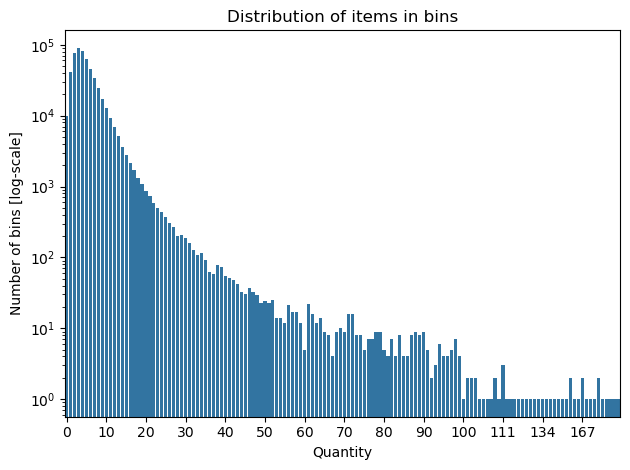

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# Use histplot instead
ax = sns.countplot(
    data=df, 
    x="quantity",
    order=sorted(df["quantity"].dropna().unique())
)

ax.set_title("Distribution of items in bins")

# X axis
ax.set_xlabel("Quantity")
x_ticks = ax.get_xticks()
ax.set_xticks([x for x in range(x_ticks[0], x_ticks[-1] + 1, 10)])

# Y axis
ax.set_ylabel("Number of bins [log-scale]")
ax.set_yscale("log")

plt.tight_layout()
plt.show()

We can see that:
* quantity ranges between *0* and *209* items
* distribution of items in bins is right-skewed (mean > median)

### Spliting data into subsets
In this step we are going to split images into train, validation, test. We are going to split that with proportion 70% : 15% : 15% across number of items in bins, so for each number we have the same proportions.

First, let's assign subset for each tuple:

In [2]:
from sklearn.model_selection import train_test_split

train_df, temp = train_test_split(df, test_size=0.3, stratify=df['quantity'], random_state=42)
validation_df, test_df = train_test_split(temp, test_size=0.5, stratify=temp['quantity'], random_state=42)


Now, we can construct destination path:

In [3]:
df['target_filepath'] = df.apply(
    lambda row: f"dataset/{row['subset']}/{row['quantity']}/{row['image_filepath'].split('/')[1]}",
    axis=1
)

In [4]:
df.head(10)

,image_filepath,quantity,subset,target_filepath
0,bin-images/00001.jpg,12,train,dataset/train/12/00001.jpg
1,bin-images/00002.jpg,17,test,dataset/test/17/00002.jpg
2,bin-images/00003.jpg,16,train,dataset/train/16/00003.jpg
3,bin-images/00004.jpg,5,train,dataset/train/5/00004.jpg
4,bin-images/00005.jpg,4,train,dataset/train/4/00005.jpg
5,bin-images/00006.jpg,5,train,dataset/train/5/00006.jpg
6,bin-images/00007.jpg,4,validation,dataset/validation/4/00007.jpg
7,bin-images/00008.jpg,19,train,dataset/train/19/00008.jpg
8,bin-images/00009.jpg,1,train,dataset/train/1/00009.jpg
9,bin-images/00010.jpg,4,train,dataset/train/4/00010.jpg


### Copy images to workspace S3 Bucket
Now it's time to copy dataset from source S3 Bucket to workspace S3 Bucket with split for train, validation and test datasets:

In [ ]:
import boto3

from botocore.config import Config
from concurrent.futures import ThreadPoolExecutor, as_completed

MAX_WORKERS = 16

s3_client = boto3.client("s3", region_name="us-east-1", config=Config(max_pool_connections=MAX_WORKERS))

def copy_file(item):
    source_path, destination_path = item

    try:
        s3_client.copy_object(
            Bucket=WORKSPACE_S3_BUCKET,
            Key=destination_path,
            CopySource={
                "Bucket": DATASET_S3_BUCKET,
                "Key": source_path
            },
        )
        return True
    except Exception as e:
        print(f'Unable to copy: {DATASET_S3_BUCKET}/{source_path} to {WORKSPACE_S3_BUCKET}/{destination_path} Failure: {e}')
        return False

items = list(df[['image_filepath', 'target_filepath']].itertuples(index=False, name=None))

with ThreadPoolExecutor(max_workers=MAX_WORKERS) as thread_pool:
    futures = [thread_pool.submit(copy_file, item) for item in items]
    for future in as_completed(futures):
        future.result()

Excellent! Now, we are ready to start training.

## Train baseline model

In this section, we are going to train baseline model: **ResNet18** adjusted for regression problem. Weights of backbone of this model are freezed for training and only last layer is trained. See `src/train.py` for more details:

In [1]:
from sagemaker.core import image_uris
from sagemaker.core.helper.session_helper import Session, get_execution_role
from sagemaker.serve import ModelBuilder
from sagemaker.serve.mode.function_pointers import Mode
from sagemaker.serve.utils.types import ModelServer
from sagemaker.train import ModelTrainer
from sagemaker.train.configs import Compute, InputData, SourceCode, StoppingCondition
from sagemaker.train.distributed import Torchrun

Let's define few constants and let's get image for training:

In [2]:
AWS_REGION = Session().boto_region_name
INSTANCE_TYPE = 'ml.g4dn.xlarge'
ROLE = get_execution_role()
WORKSPACE_S3_BUCKET = Session().default_bucket()

training_image = image_uris.retrieve(
    framework="pytorch",
    region=AWS_REGION,
    version="2.6",
    py_version="py312",
    instance_type=INSTANCE_TYPE,
    image_scope="training",
)

INFO:sagemaker.config:Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
INFO:sagemaker.config:Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


Now, we can define our training:

In [3]:
trainer = ModelTrainer(
    training_image=training_image,
    source_code=SourceCode(
        source_dir="./src",
        entry_script="train.py"
    ),
    role=ROLE,
    compute=Compute(
        instance_type=INSTANCE_TYPE,
        instance_count=2
    ),
    stopping_condition=StoppingCondition(max_runtime_in_seconds=7200),
    base_job_name='resnet18',
    hyperparameters={
        'batch-size': 512,
        'lr': 0.003,
        'epochs': 5,
        'no-improvement-threshold': 2,
        'resnet-version': 'resnet18'
    },
    distributed=Torchrun()
)

INFO:sagemaker.core.utils.utils:SageMaker session not provided. Using default Session.
INFO:sagemaker.core.helper.iam_role_resolver:Cannot simulate policies for 'arn:aws:iam::606487093675:role/service-role/AmazonSageMaker-ExecutionRole-20261116T194534' (access denied); permission verdict unknown.
INFO:sagemaker.core.utils.utils:OutputDataConfig not provided. Using default:
s3_output_path='s3://sagemaker-us-east-1-606487093675/resnet18' kms_key_id=None compression_type='GZIP'
INFO:sagemaker.core.utils.utils:Training image URI: 763104351884.dkr.ecr.us-east-1.amazonaws.com/pytorch-training:2.6-gpu-py312


and now, let's start training:

In [4]:
trainer.train(
    input_data_config=[
        InputData(
            channel_name="train", 
            data_source=f"s3://{WORKSPACE_S3_BUCKET}/dataset/train/",
            content_type="application/x-image"
        ),
        InputData(
            channel_name="validation", 
            data_source=f"s3://{WORKSPACE_S3_BUCKET}/dataset/validation/",
            content_type="application/x-image"
        )
    ], 
    wait=True
)

INFO:sagemaker.core.telemetry.telemetry_logging:SageMaker Python SDK will collect telemetry to help us better understand our user's needs, diagnose issues, and deliver additional features.
To opt out of telemetry, please disable via TelemetryOptOut parameter in SDK defaults config. For more information, refer to https://sagemaker.readthedocs.io/en/stable/overview.html#configuring-and-using-defaults-with-the-sagemaker-python-sdk.
INFO:sagemaker.core.utils.utils:Training Job Name: resnet18-20261120202724
INFO:sagemaker.config:Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
INFO:sagemaker.config:Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml
INFO:sagemaker.core.resources:Creating training_job resource.


Output()

Starting training script
...Starting training with the following parameters: Batch size: 512 Epochs: 5 Learning rate: 0.003


Now, let's see loss value convergence curve from training:

![](assets/resnet-loss.png)

In both cases we can see that loss decreases. On validation dataset we obtained loss above *1.7* which is average error that model does. Since this plot doesn't show that loss did not stop decreasing, most probably we could try to obtain slight better model if we would spend more time on training.

Now, let's try to see how our model performs on test subset, we will setup *Batch Transform Job* on obtained model:

In [ ]:
# Get image ARN for inference
INFERENCE_IMAGE_URI = image_uris.retrieve(
    framework="pytorch",
    region=AWS_REGION,
    version="2.6.0",
    py_version="py312",
    instance_type=INSTANCE_TYPE,
    image_scope="inference",
)

model_builder = ModelBuilder(
    image_uri=INFERENCE_IMAGE_URI,
    model_server=ModelServer.TORCHSERVE,
    source_code=SourceCode(
        source_dir="./src",
        entry_script="inference.py",
    ),
    s3_model_data_url=f's3://{WORKSPACE_S3_BUCKET}/resnet18/resnet18-20261120202724/output/model.tar.gz',
    instance_type=INSTANCE_TYPE,
    sagemaker_session=Session(),
    role_arn=ROLE,
    env_vars={
        "RESNET_VERSION": "resnet18"
    },
)

model_builder.build(model_name="resnet18")
transformer = model_builder.transformer(
    instance_count=1,
    instance_type=INSTANCE_TYPE,
    output_path=f"s3://{WORKSPACE_S3_BUCKET}/test-predictions/resnet18/",
    accept="application/json",
    env={
        "RESNET_VERSION": "resnet18"
    }
)

transformer.transform(
    data=f"s3://{WORKSPACE_S3_BUCKET}/dataset/test/",
    content_type="application/x-image",
    split_type=None
)

transformer.wait()

DEBUG:sagemaker.core.utils.utils:No ModelMetadata provided. ModelBuilder is not handling MLflow model input
INFO:sagemaker.core.helper.iam_role_resolver:Cannot simulate policies for 'arn:aws:iam::606487093675:role/service-role/AmazonSageMaker-ExecutionRole-20261116T194534' (access denied); permission verdict unknown.
INFO:sagemaker.core.helper.iam_role_resolver:Cannot simulate policies for 'arn:aws:iam::606487093675:role/service-role/AmazonSageMaker-ExecutionRole-20261116T194534' (access denied); permission verdict unknown.
INFO:sagemaker.core.utils.utils:Repacking model artifact (s3://sagemaker-us-east-1-606487093675/resnet18/resnet18-20261120202724/output/model.tar.gz), script artifact (.), and dependencies ([]) into single tar.gz file located at s3://sagemaker-us-east-1-606487093675/resnet18/model.tar.gz. This may take some time depending on model size...
INFO:sagemaker:Creating model with name: resnet18
INFO:sagemaker.core.utils.utils:✅ Model has been created: 'resnet18' using serv

Output()

Now, let's copy all response to host machine and let's construct dataframe with two columns: true value and predicted value. Based on that we can evaluate model while using MAE, RMSE and R^2:

In [ ]:
import os

os.environ["S3_BUCKET"] = WORKSPACE_S3_BUCKET
!aws s3 cp s3://${S3_BUCKET}/test-predictions/resnet18/ test_predictions/resnet18 --recursive

Completed 595.9 KiB/~600.4 KiB (6.2 KiB/s) with ~127 file(s) remaining (calculating...)

In [3]:
import os
import numpy as np
import json
import pandas as pd

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_predictions(root):
    dataframe = []

    for true_value in os.listdir(root):
        folder_dir = root / true_value
        for prediction in os.listdir(folder_dir):
            with open(folder_dir / prediction) as json_file:
                prediction = json.load(json_file)['predictions'][0]
                dataframe.append((true_value, prediction))
    
    df = pd.DataFrame(dataframe, columns=["true_value", "predicted"])

    y_true = df["true_value"]
    y_pred = df["predicted"]
    
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return (mae, rmse, r2)

In [18]:
evaluate_predictions(Path('./test_predictions/resnet18'))

(2.3564219421155808, 5.439008539245157, 0.09093804755851442)

## Model training
Now, let's employ similar procedure for our target model that utilizes **ResNet101** architecture:

In [3]:
trainer = ModelTrainer(
    training_image=training_image,
    source_code=SourceCode(
        source_dir="./src",
        entry_script="train.py"
    ),
    role=ROLE,
    compute=Compute(
        instance_type=INSTANCE_TYPE,
        instance_count=2
    ),
    stopping_condition=StoppingCondition(max_runtime_in_seconds=7200),
    base_job_name='resnet101',
    hyperparameters={
        'batch-size': 512,
        'lr': 0.003,
        'epochs': 5,
        'no-improvement-threshold': 2,
        'resnet-version': 'resnet101'
    },
    distributed=Torchrun()
)

INFO:sagemaker.core.utils.utils:SageMaker session not provided. Using default Session.
INFO:sagemaker.core.helper.iam_role_resolver:Cannot simulate policies for 'arn:aws:iam::606487093675:role/service-role/AmazonSageMaker-ExecutionRole-20261116T194534' (access denied); permission verdict unknown.
INFO:sagemaker.core.utils.utils:OutputDataConfig not provided. Using default:
s3_output_path='s3://sagemaker-us-east-1-606487093675/resnet101' kms_key_id=None compression_type='GZIP'
INFO:sagemaker.core.utils.utils:Training image URI: 763104351884.dkr.ecr.us-east-1.amazonaws.com/pytorch-training:2.6-gpu-py312


In [4]:
trainer.train(
    input_data_config=[
        InputData(
            channel_name="train",
            data_source=f"s3://{WORKSPACE_S3_BUCKET}/dataset/train/",
            content_type="application/x-image"
        ),
        InputData(
            channel_name="validation",
            data_source=f"s3://{WORKSPACE_S3_BUCKET}/dataset/validation/",
            content_type="application/x-image"
        )
    ],
    wait=True
)

INFO:sagemaker.core.telemetry.telemetry_logging:SageMaker Python SDK will collect telemetry to help us better understand our user's needs, diagnose issues, and deliver additional features.
To opt out of telemetry, please disable via TelemetryOptOut parameter in SDK defaults config. For more information, refer to https://sagemaker.readthedocs.io/en/stable/overview.html#configuring-and-using-defaults-with-the-sagemaker-python-sdk.
INFO:sagemaker.core.utils.utils:Training Job Name: resnet101-20261121131844
INFO:sagemaker.config:Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
INFO:sagemaker.config:Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml
INFO:sagemaker.core.resources:Creating training_job resource.


Output()

Starting training script
Starting training with the following parameters: Batch size: 512 Epochs: 5 Learning rate: 0.003
Epoch 1/5
...Epoch [5] Train Avg Loss: 1.74262447
Epoch [5] Validation Avg Loss: 1.70984651
++ echo 'Training Container Execution Completed'
Training Container Execution Completed
Epoch [5] Validation Avg Loss: 1.70984651
Training Container Execution Completed
++ echo 'Training Container Execution Completed'
INFO:sagemaker.core.resources:Final Resource Status: [bold]Completed


![](assets/resnet-101-loss.png)

Now, let's evaluate new model:

In [ ]:
INFERENCE_IMAGE_URI = image_uris.retrieve(
    framework="pytorch",
    region=AWS_REGION,
    version="2.6.0",
    py_version="py312",
    instance_type=INSTANCE_TYPE,
    image_scope="inference",
)

model_builder = ModelBuilder(
    image_uri=INFERENCE_IMAGE_URI,
    model_server=ModelServer.TORCHSERVE,
    source_code=SourceCode(
        source_dir="./src",
        entry_script="inference.py",
    ),
    s3_model_data_url=f's3://{WORKSPACE_S3_BUCKET}/resnet101/resnet101-20261121131844/output/model.tar.gz',
    instance_type=INSTANCE_TYPE,
    sagemaker_session=Session(),
    role_arn=ROLE,
    env_vars={
        "RESNET_VERSION": "resnet101"
    },
)

model_builder.build(model_name="resnet101")
transformer = model_builder.transformer(
    instance_count=1,
    instance_type=INSTANCE_TYPE,
    output_path=f"s3://{WORKSPACE_S3_BUCKET}/test-predictions/resnet101/",
    accept="application/json"
)

transformer.transform(
    data=f"s3://{WORKSPACE_S3_BUCKET}/dataset/test/",
    content_type="application/x-image",
    split_type=None
)

transformer.wait()

DEBUG:sagemaker.core.utils.utils:No ModelMetadata provided. ModelBuilder is not handling MLflow model input
INFO:sagemaker.core.helper.iam_role_resolver:Cannot simulate policies for 'arn:aws:iam::606487093675:role/service-role/AmazonSageMaker-ExecutionRole-20261116T194534' (access denied); permission verdict unknown.
INFO:sagemaker.core.helper.iam_role_resolver:Cannot simulate policies for 'arn:aws:iam::606487093675:role/service-role/AmazonSageMaker-ExecutionRole-20261116T194534' (access denied); permission verdict unknown.
INFO:sagemaker.core.utils.utils:Repacking model artifact (s3://sagemaker-us-east-1-606487093675/resnet101/resnet101-20261121131844/output/model.tar.gz), script artifact (./src), and dependencies ([]) into single tar.gz file located at s3://sagemaker-us-east-1-606487093675/resnet101/model.tar.gz. This may take some time depending on model size...
INFO:sagemaker:Creating model with name: resnet101
DEBUG:sagemaker.core.utils.utils:No config provided. Using default conf

Output()

...

In [6]:
import os

os.environ["S3_BUCKET"] = WORKSPACE_S3_BUCKET

In [ ]:
%%bash

aws s3 cp s3://${S3_BUCKET}/test-predictions/resnet101/ test_predictions/resnet101 --recursive

In [4]:
evaluate_predictions(Path('./test_predictions/resnet101'))

(2.2804975791999444, 5.3980573735633035, 0.10457546025596975)

## Results

| Model      | MAE                | RMSE               | R^2                 |
| ---------- | ------------------ | ------------------ | ------------------- |
| Resnet18   | 2.3564219421155808 | 5.4390085392451570 | 0.09093804755851442 |
| Resnet101  | 2.2804975791999444 | 5.3980573735633035 | 0.10457546025596975 |